In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from statsmodels.stats.outliers_influence import variance_inflation_factor

df = pd.read_csv("../data/housing.csv")

print("Размер датасета:", df.shape)
display(df.head())
print("\nПропущенные значения:")
print(df.isnull().sum())

Размер датасета: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422



Пропущенные значения:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [4]:
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (16512, 8)
Тестовая выборка: (4128, 8)


In [5]:
baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

print("Базовая модель:")
print(f"MAE: {baseline_mae:.4f}")
print(f"RMSE: {baseline_rmse:.4f}")
print(f"R²: {baseline_r2:.4f}")

Базовая модель:
MAE: 0.5332
RMSE: 0.7456
R²: 0.5758


In [6]:
def calculate_vif(features):
    values = features.to_numpy(dtype=float)

    return pd.DataFrame({
        "Feature": features.columns,
        "VIF": [
            variance_inflation_factor(values, i)
            for i in range(values.shape[1])
        ]
    }).sort_values("VIF", ascending=False)


vif_table = calculate_vif(X_train)

display(vif_table)

,Feature,VIF
6,Latitude,9.206134
7,Longitude,8.875984
2,AveRooms,7.917240
3,AveBedrms,6.609200
0,MedInc,2.539815
1,HouseAge,1.237337
4,Population,1.134824
5,AveOccup,1.009733


In [7]:
reduced_features = list(X_train.columns)

while len(reduced_features) > 2:
    current_vif = calculate_vif(X_train[reduced_features])
    max_vif = current_vif["VIF"].max()

    if max_vif <= 10:
        break

    feature_to_remove = current_vif.iloc[0]["Feature"]

    print(
        f"Удаляем {feature_to_remove}, "
        f"VIF = {max_vif:.2f}"
    )

    reduced_features.remove(feature_to_remove)

print("\nОставшиеся признаки:")
print(reduced_features)

print("\nVIF после отбора:")
display(calculate_vif(X_train[reduced_features]))


Оставшиеся признаки:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

VIF после отбора:


,Feature,VIF
6,Latitude,9.206134
7,Longitude,8.875984
2,AveRooms,7.917240
3,AveBedrms,6.609200
0,MedInc,2.539815
1,HouseAge,1.237337
4,Population,1.134824
5,AveOccup,1.009733


In [8]:
reduced_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])

reduced_model.fit(X_train[reduced_features], y_train)

reduced_predictions = reduced_model.predict(X_test[reduced_features])

reduced_mae = mean_absolute_error(y_test, reduced_predictions)
reduced_rmse = np.sqrt(mean_squared_error(y_test, reduced_predictions))
reduced_r2 = r2_score(y_test, reduced_predictions)

print("Модель с сокращённым набором признаков:")
print(f"MAE: {reduced_mae:.4f}")
print(f"RMSE: {reduced_rmse:.4f}")
print(f"R²: {reduced_r2:.4f}")

Модель с сокращённым набором признаков:
MAE: 0.5332
RMSE: 0.7456
R²: 0.5758


In [9]:
comparison = pd.DataFrame({
    "Model": ["Baseline", "Reduced"],
    "Number of features": [
        len(X_train.columns),
        len(reduced_features)
    ],
    "MAE": [baseline_mae, reduced_mae],
    "RMSE": [baseline_rmse, reduced_rmse],
    "R2": [baseline_r2, reduced_r2]
})

display(comparison.round(4))

comparison.to_csv("../results/model_comparison.csv", index=False)

,Model,Number of features,MAE,RMSE,R2
0,Baseline,8,0.5332,0.7456,0.5758
1,Reduced,8,0.5332,0.7456,0.5758


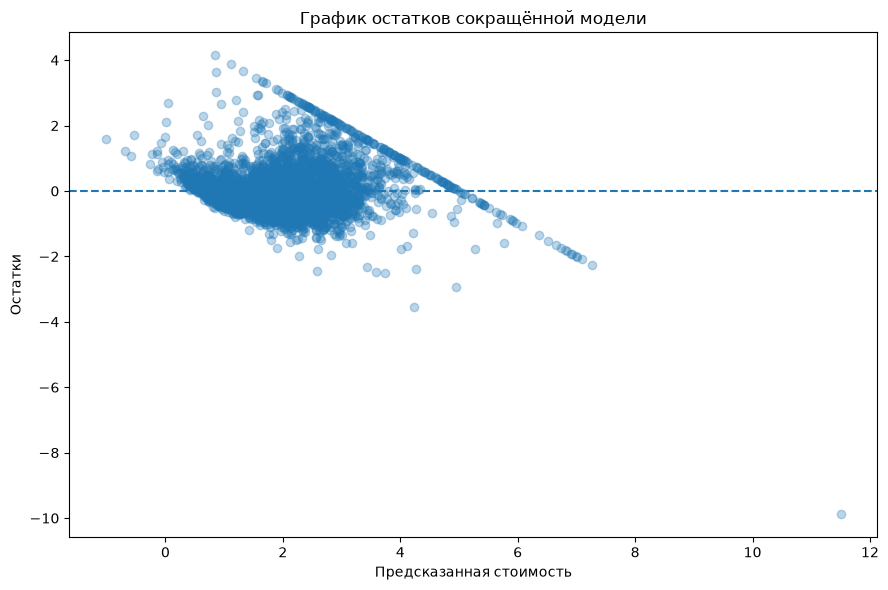

In [10]:
residuals = y_test - reduced_predictions

plt.figure(figsize=(9, 6))

plt.scatter(
    reduced_predictions,
    residuals,
    alpha=0.3
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Предсказанная стоимость")
plt.ylabel("Остатки")
plt.title("График остатков сокращённой модели")

plt.tight_layout()
plt.savefig("../results/residuals.png", dpi=150)
plt.show()

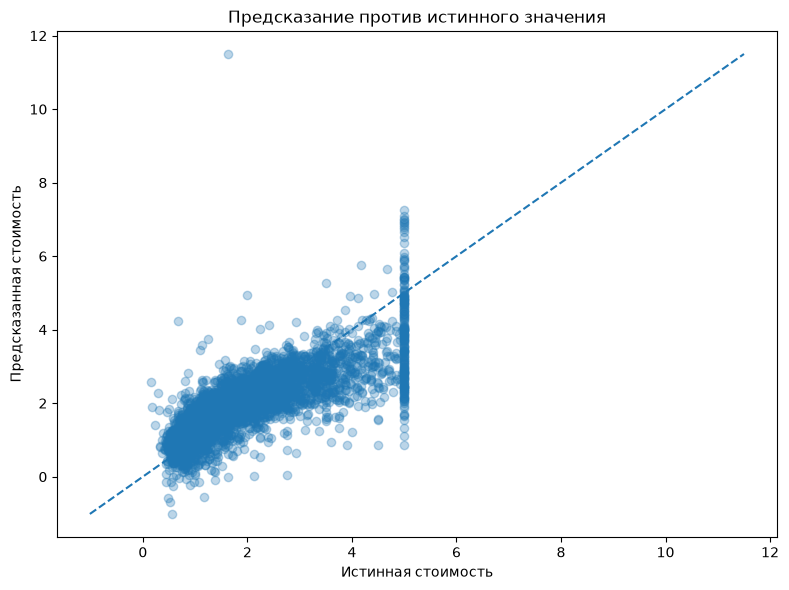

In [11]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    reduced_predictions,
    alpha=0.3
)

lower = min(y_test.min(), reduced_predictions.min())
upper = max(y_test.max(), reduced_predictions.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--"
)

plt.xlabel("Истинная стоимость")
plt.ylabel("Предсказанная стоимость")
plt.title("Предсказание против истинного значения")

plt.tight_layout()
plt.savefig("../results/prediction_vs_actual.png", dpi=150)
plt.show()

In [ ]:

mae_base_dollars = baseline_mae * 100_000
mae_reduced_dollars = reduced_mae * 100_000

if reduced_mae < baseline_mae and reduced_r2 >= baseline_r2:
    decision = (
        "сокращённая модель, поскольку она уменьшила среднюю "
        "ошибку и не снизила R²"
    )
elif baseline_mae < reduced_mae and baseline_r2 >= reduced_r2:
    decision = (
        "базовая модель, поскольку она показала меньшую ошибку "
        "и не уступила по R²"
    )
else:
    decision = (
        "модель с учётом компромисса между качеством предсказаний "
        "и количеством признаков"
    )

if reduced_mae < baseline_mae:
    quality = "улучшило"
elif np.isclose(reduced_mae, baseline_mae, rtol=0.01):
    quality = "незначительно изменило"
else:
    quality = "ухудшило"

markdown_report = f"""
## Выводы

В ходе практической работы была построена модель линейной
регрессии для предсказания стоимости жилья в Калифорнии.

Базовая модель использовала {len(X_train.columns)} признаков.
Для оценки качества на тестовой выборке были рассчитаны MAE,
RMSE и R².

Для анализа мультиколлинеарности была построена корреляционная
матрица и рассчитан VIF. После анализа признаков была обучена
сокращённая модель, использующая {len(reduced_features)} признаков:
{", ".join(reduced_features)}.

MAE базовой модели составила {baseline_mae:.4f},
а сокращённой модели — {reduced_mae:.4f}.

Средняя абсолютная ошибка в денежном выражении составила
приблизительно ${mae_base_dollars:,.0f} для базовой модели
и ${mae_reduced_dollars:,.0f} для сокращённой модели.
Целевая переменная измеряется в единицах по $100 000.

RMSE базовой модели составила {baseline_rmse:.4f},
а сокращённой — {reduced_rmse:.4f}.
Значение R² базовой модели составило {baseline_r2:.4f},
а сокращённой — {reduced_r2:.4f}.

По результатам сравнения {decision}.
При окончательном выборе также необходимо учитывать
результаты анализа остатков.

График остатков сокращённой модели построен для проверки
наличия систематических закономерностей в ошибках.
Его следует оценить визуально: отсутствие выраженного
паттерна поддерживает применение линейной модели,
а кривизна или изменение разброса указывают на возможные
нарушения её допущений.

Таким образом, сокращение числа признаков {quality}
качество по MAE. Итоговый выбор модели должен учитывать
также RMSE, R² и график остатков.
"""

print(markdown_report)


## Выводы

В ходе практической работы была построена модель линейной
регрессии для предсказания стоимости жилья в Калифорнии.

Базовая модель использовала 8 признаков.
Для оценки качества на тестовой выборке были рассчитаны MAE,
RMSE и R².

Для анализа мультиколлинеарности была построена корреляционная
матрица и рассчитан VIF. После анализа признаков была обучена
сокращённая модель, использующая 8 признаков:
MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup, Latitude, Longitude.

MAE базовой модели составила 0.5332,
а сокращённой модели — 0.5332.

Средняя абсолютная ошибка в денежном выражении составила
приблизительно $53,320 для базовой модели
и $53,320 для сокращённой модели.
Целевая переменная измеряется в единицах по $100 000.

RMSE базовой модели составила 0.7456,
а сокращённой — 0.7456.
Значение R² базовой модели составило 0.5758,
а сокращённой — 0.5758.

По результатам сравнения модель с учётом компромисса между качеством предсказаний и количеством признаков.
При окон


## Выводы

В ходе практической работы была построена модель линейной
регрессии для предсказания стоимости жилья в Калифорнии.

Базовая модель использовала 8 признаков.
Для оценки качества на тестовой выборке были рассчитаны MAE,
RMSE и R².

Для анализа мультиколлинеарности была построена корреляционная
матрица и рассчитан VIF. После анализа признаков была обучена
сокращённая модель, использующая 8 признаков:
MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup, Latitude, Longitude.

MAE базовой модели составила 0.5332,
а сокращённой модели — 0.5332.

Средняя абсолютная ошибка в денежном выражении составила
приблизительно $53,320 для базовой модели
и $53,320 для сокращённой модели.
Целевая переменная измеряется в единицах по $100 000.

RMSE базовой модели составила 0.7456,
а сокращённой — 0.7456.
...
Таким образом, сокращение числа признаков незначительно изменило
качество по MAE. Итоговый выбор модели должен учитывать
также RMSE, R² и график остатков.

Output is truncated. View as a scrollable element or open in a text editor. Adjust cell output settings...